In [1]:
import sys, json, warnings, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve()
while not (ROOT / 'requirements.txt').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import optuna
from src.evaluation import baseline_comparison as B, feature_selection as F, nested_tuning as N, run_feature_selection as R
from src.models import tuning as T
from src.models.baselines import REGISTRY

pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_rows', 120, 'display.max_colwidth', 120)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / 'reports' / 'tables'
OUT = N.OUT
df, X, y, folds = R.load()
O = pd.read_csv(OUT / 'nested_outer_folds.csv'); TR = pd.read_csv(OUT / 'nested_trials.csv'); IMP = pd.read_csv(OUT / 'nested_param_importance.csv')
PRED = pd.read_csv(OUT / 'nested_predictions.csv.gz'); FT = pd.read_csv(OUT / 'final_trials.csv')
FINAL = json.loads((OUT / f'final_params_{N.EXPERIMENT_ID}.json').read_text()); META = json.loads((OUT / 'run_metadata.json').read_text())
BASE = pd.read_csv(B.OUT / 'expA_folds.csv')
NAME = {'elasticnet': 'ElasticNet', 'gbr': 'Gradient Boosting'}
BASEKEY = {'elasticnet': 'elasticnet', 'gbr': 'gbr'}
print('experiment', META['experiment_id'], '| optuna', optuna.__version__, '| outer folds', O.fold.nunique(), '| families', list(O.family.unique()))

experiment tuning_v1 | optuna 5.0.0 | outer folds 15 | families ['elasticnet', 'gbr']


In [2]:
bt = pd.read_csv(TAB / 'baseline_comparison.csv', index_col=0)
display(bt.round({'Log-RMSE Mean': 4, 'Log-RMSE SD': 4, 'MAE USD': 0, 'RMSE USD': 0, 'MAPE %': 2, 'R2 USD': 3, 'Fit Time s': 2}))

,Log-RMSE Mean,Log-RMSE SD,MAE USD,RMSE USD,MAPE %,R2 USD,Fit Time s
Model,,,,,,,
ElasticNet,0.1289,0.0203,15814.0,31733.0,8.88,0.825,0.52
Lasso,0.1295,0.0204,16011.0,31768.0,8.96,0.825,0.51
Gradient Boosting,0.1311,0.0154,16246.0,28248.0,9.16,0.869,1.93
Ridge,0.1322,0.0210,16104.0,32526.0,9.07,0.816,0.52
OLS,0.1341,0.0207,16362.0,32688.0,9.22,0.816,0.50
Random Forest,0.1423,0.0094,17640.0,30070.0,9.90,0.855,13.61
Dummy (mean),0.3992,0.0126,55622.0,80341.0,32.49,-0.032,0.02


In [3]:
rows = []
why = {('elasticnet', 'alpha'): 'regularisation strength; effect is multiplicative, so log scale. Brackets the 6e-4..7.5e-4 seen earlier by 2 decades down and 4 up (alpha 1e1 shrinks everything to zero)',
       ('elasticnet', 'l1_ratio'): 'L1/L2 mix; linear scale; 0.1-0.9 excludes the pure Ridge/Lasso limits, which the baselines showed add nothing',
       ('gbr', 'n_estimators'): 'boosting rounds; step 25 keeps the space discrete and cheap; 500 caps cost on a laptop',
       ('gbr', 'learning_rate'): 'shrinkage; log scale, trades off against n_estimators; default 0.1 sits inside',
       ('gbr', 'max_depth'): 'interaction order; 2-5 keeps weak learners shallow (default 3)',
       ('gbr', 'subsample'): 'stochastic boosting fraction; below 0.6 is noisy at n=1,168 training rows',
       ('gbr', 'min_samples_leaf'): 'leaf size regulariser; 1-15 (default 1)'}
for fam, sp in T.SPACES.items():
    for p, (lo, hi, kind) in sp.items():
        rows.append(dict(family=NAME[fam], parameter=p, low=lo, high=hi, scale=kind, justification=why[(fam, p)]))
display(pd.DataFrame(rows).set_index(['family', 'parameter']))
print('fixed (not tuned): ElasticNet max_iter =', T.MAX_ITER, '(convergence control; ConvergenceWarnings are counted per trial); random_state = 42 everywhere; scaling: robust for ElasticNet, none for GBR')

low   high         scale                                                                                                            justification
family            parameter                                                                                                                                                               
ElasticNet        alpha              0.00001   10.0           log  regularisation strength; effect is multiplicative, so log scale. Brackets the 6e-4..7.5e-4 seen earlier by 2 decades...
                  l1_ratio           0.10000    0.9         float            L1/L2 mix; linear scale; 0.1-0.9 excludes the pure Ridge/Lasso limits, which the baselines showed add nothing
Gradient Boosting n_estimators      50.00000  500.0  int(step 25)                                   boosting rounds; step 25 keeps the space discrete and cheap; 500 caps cost on a laptop
                  learning_rate      0.01000    0.2           log                                           shrinkage; log scale, trades off against n_estimators; default 0.1 sits inside
                  max_depth          2.00000    5.0           int                                                           interaction order; 2-5 keeps weak learners shallow (default 3)
                  subsample          0.60000    1.0         float                                                stochastic boosting fraction; below 0.6 is noisy at n=1,168 training rows
                  min_samples_leaf   1.00000   15.0           int                                                                                  leaf size regulariser; 1-15 (default 1)

fixed (not tuned): ElasticNet max_iter = 100000 (convergence control; ConvergenceWarnings are counted per trial); random_state = 42 everywhere; scaling: robust for ElasticNet, none for GBR


In [4]:
pilot = pd.read_csv(OUT / 'pilot_trials.csv')
print('Pilot (outer fold 1 only, 12 trials per family, used for timing only):')
display(pilot.groupby('family').agg(trials=('number', 'size'), mean_trial_s=('duration_s', 'mean'), max_trial_s=('duration_s', 'max'), failed=('state', lambda s: int((s != 'COMPLETE').sum()))).round(3))
bud = TR.groupby('family').agg(trials_total=('number', 'size'), outer_folds=('outer_fold', 'nunique'), failed=('state', lambda s: int((s == 'FAIL').sum())),
                               convergence_warnings=('user_attrs_n_convergence_warnings', 'sum'), mean_trial_s=('duration_s', 'mean'))
bud['trials_per_study'] = bud.trials_total / bud.outer_folds
display(bud.rename(index=NAME).round(3))

Pilot (outer fold 1 only, 12 trials per family, used for timing only):


,trials,mean_trial_s,max_trial_s,failed
family,,,,
elasticnet,12,0.036,0.113,0
gbr,12,6.004,11.998,0


,trials_total,outer_folds,failed,convergence_warnings,mean_trial_s,trials_per_study
family,,,,,,
ElasticNet,2250,15,0,0,0.201,150.0
Gradient Boosting,750,15,0,0,5.861,50.0


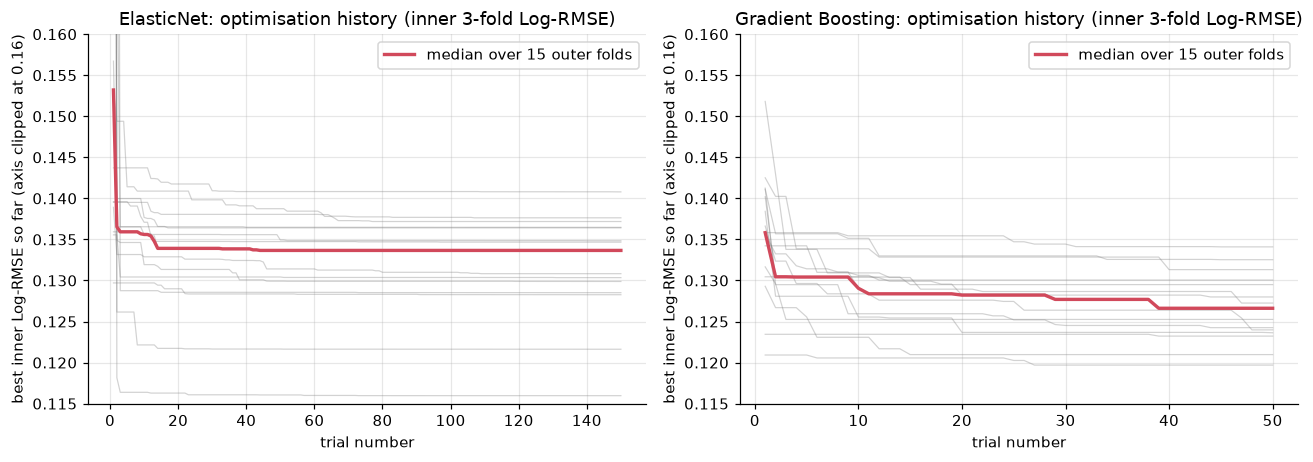

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, fam in zip(axes, ['elasticnet', 'gbr']):
    d = TR[TR.family == fam]
    for k, g in d.groupby('outer_fold'):
        ax.plot(g.number + 1, g.best_so_far, color='grey', alpha=.35, lw=.8)
    med = d.groupby('number').best_so_far.median()
    ax.plot(med.index + 1, med.values, color='#d1495b', lw=2.2, label='median over 15 outer folds')
    ax.set_ylim(.115, .16); ax.set_title(f'{NAME[fam]}: optimisation history (inner 3-fold Log-RMSE)'); ax.set_xlabel('trial number'); ax.set_ylabel('best inner Log-RMSE so far (axis clipped at 0.16)'); ax.legend()
plt.tight_layout(); plt.savefig(FIG / 'tuning_fig1_history.png'); plt.show()

In [6]:
fin = pd.DataFrame({NAME[f]: dict(trials=v['n_trials'], inner_cv_best_logrmse=v['inner_cv_best_logrmse'], seconds=v['seconds'], **v['params']) for f, v in FINAL.items()}).T
display(fin)
print('Final-study optimum (all 1,460 rows, inner 3-fold): an optimistic, in-sample selection score; NOT a generalisation estimate and NOT evaluated by the nested CV.')

,trials,inner_cv_best_logrmse,seconds,alpha,l1_ratio,n_estimators,learning_rate,max_depth,subsample,min_samples_leaf
ElasticNet,300.0,0.129673,116.8,0.000943,0.899913,NaN,NaN,NaN,NaN,NaN
Gradient Boosting,100.0,0.127093,499.1,NaN,NaN,500.0,0.024156,4.0,0.654877,4.0


Final-study optimum (all 1,460 rows, inner 3-fold): an optimistic, in-sample selection score; NOT a generalisation estimate and NOT evaluated by the nested CV.


In [7]:
met = ['rmse_log', 'mae', 'rmse_usd', 'mape', 'r2_usd']
summ = O.groupby('family')[met].agg(['mean', 'std'])
tab = pd.DataFrame({NAME[f]: {'Log-RMSE mean': O[O.family == f].rmse_log.mean(), 'Log-RMSE SD': O[O.family == f].rmse_log.std(), 'MAE USD': O[O.family == f].mae.mean(),
                              'RMSE USD': O[O.family == f].rmse_usd.mean(), 'MAPE %': O[O.family == f].mape.mean(), 'R2 USD': O[O.family == f].r2_usd.mean(),
                              'R2 log-scale': O[O.family == f].r2_log.mean(), 'inner best Log-RMSE (mean)': O[O.family == f].inner_best.mean(),
                              'tuning time per outer fold, s': O[O.family == f].tune_time.mean()} for f in ['elasticnet', 'gbr']}).T
display(tab.round({'Log-RMSE mean': 4, 'Log-RMSE SD': 4, 'MAE USD': 0, 'RMSE USD': 0, 'MAPE %': 2, 'R2 USD': 3, 'R2 log-scale': 3, 'inner best Log-RMSE (mean)': 4, 'tuning time per outer fold, s': 0}))
cols = ['family', 'fold', 'rmse_log', 'mae', 'rmse_usd', 'mape', 'r2_usd', 'inner_best', 'n_failed', 'n_convergence_warnings'] + [c for c in O.columns if c.startswith('best_')]
O[cols].round(4).to_csv(TAB / 'tuning_nested_fold_level.csv', index=False)
display(O[cols].round(4))

,Log-RMSE mean,Log-RMSE SD,MAE USD,RMSE USD,MAPE %,R2 USD,R2 log-scale,inner best Log-RMSE (mean),"tuning time per outer fold, s"
ElasticNet,0.1307,0.0209,16125.0,32014.0,9.06,0.822,0.891,0.1318,34.0
Gradient Boosting,0.1260,0.0126,15535.0,26774.0,8.76,0.884,0.900,0.1267,295.0


,family,fold,rmse_log,mae,rmse_usd,mape,r2_usd,inner_best,n_failed,n_convergence_warnings,best_alpha,best_l1_ratio,best_n_estimators,best_learning_rate,best_max_depth,best_subsample,best_min_samples_leaf
0,elasticnet,0,0.1063,14882.0551,24673.2967,8.0162,0.9069,0.1347,0,0,0.0009,0.8684,NaN,NaN,NaN,NaN,NaN
1,elasticnet,1,0.1234,15359.8487,23025.6212,8.9663,0.9105,0.1303,0,0,0.0010,0.8576,NaN,NaN,NaN,NaN,NaN
2,elasticnet,2,0.1168,13955.8684,20810.5782,8.3224,0.9181,0.1285,0,0,0.0010,0.6731,NaN,NaN,NaN,NaN,NaN
3,elasticnet,3,0.1212,15456.8685,24187.4086,8.6281,0.8947,0.1299,0,0,0.0011,0.7711,NaN,NaN,NaN,NaN,NaN
4,elasticnet,4,0.1758,20060.3582,65391.9065,10.9407,0.4783,0.1160,0,0,0.0040,0.1388,NaN,NaN,NaN,NaN,NaN
5,elasticnet,5,0.1135,15199.0256,22297.8433,8.5461,0.9167,0.1337,0,0,0.0009,0.8724,NaN,NaN,NaN,NaN,NaN
6,elasticnet,6,0.1553,18929.4634,40285.0483,10.3839,0.7962,0.1372,0,0,0.0180,0.1011,NaN,NaN,NaN,NaN,NaN
7,elasticnet,7,0.1470,16706.7624,53616.8550,9.2826,0.5689,0.1283,0,0,0.0045,0.1041,NaN,NaN,NaN,NaN,NaN
8,elasticnet,8,0.1302,15082.1027,20769.4309,9.3647,0.9051,0.1376,0,0,0.0188,0.1004,NaN,NaN,NaN,NaN,NaN
9,elasticnet,9,0.1198,16373.8949,27145.8376,8.6227,0.8839,0.1348,0,0,0.0109,0.1013,NaN,NaN,NaN,NaN,NaN


In [8]:
rows, paired = [], {}
for f in ['elasticnet', 'gbr']:
    t = O[O.family == f].sort_values('fold').reset_index(drop=True)
    b = BASE[BASE.model == BASEKEY[f]].sort_values('fold').reset_index(drop=True)
    p = F.paired_vs_reference({'baseline': b, 'tuned': t}, 'baseline'); paired[f] = (b, t, p.loc['tuned'])
    rows.append({'Model': NAME[f], 'Baseline Log-RMSE': b.rmse_log.mean(), 'Tuned Log-RMSE': t.rmse_log.mean(), 'Difference (tuned - baseline)': p.loc['tuned', 'diff'],
                 '95% corrected interval': f"{p.loc['tuned', 'ci_lo']:+.4f} to {p.loc['tuned', 'ci_hi']:+.4f}", 'folds tuned better': f"{int(p.loc['tuned', 'folds_better'])}/15",
                 'repeats tuned better': f"{int(p.loc['tuned', 'repeats_better'])}/3", 'MAE USD': t.mae.mean(), 'RMSE USD': t.rmse_usd.mean(), 'MAPE %': t.mape.mean(), 'R2 USD': t.r2_usd.mean(),
                 'verdict (pre-set rule)': p.loc['tuned', 'verdict']})
CMP = pd.DataFrame(rows).set_index('Model')
display(CMP.round({'Baseline Log-RMSE': 4, 'Tuned Log-RMSE': 4, 'Difference (tuned - baseline)': 4, 'MAE USD': 0, 'RMSE USD': 0, 'MAPE %': 2, 'R2 USD': 3}))
CMP.to_csv(TAB / 'tuning_vs_baseline.csv')
print('Baseline USD metrics for reference:'); display(BASE[BASE.model.isin(['elasticnet', 'gbr'])].groupby('model')[['mae', 'rmse_usd', 'mape', 'r2_usd']].mean().round(3))
b2 = BASE[BASE.model == 'gbr_nb03'].sort_values('fold').reset_index(drop=True)
p2 = F.paired_vs_reference({'gbr_nb03 (previously informed, fixed)': b2, 'tuned GBR': paired['gbr'][1]}, 'gbr_nb03 (previously informed, fixed)').loc['tuned GBR']
print(f"Tuned GBR vs the previously informed fixed GBR (gbr_nb03): difference {p2['diff']:+.4f}, interval {p2.ci_lo:+.4f} to {p2.ci_hi:+.4f}, {int(p2.folds_better)}/15 folds better -> {p2.verdict}")
e, g = paired['elasticnet'][1], paired['gbr'][1]
pg = F.paired_vs_reference({'tuned ElasticNet': e, 'tuned GBR': g}, 'tuned ElasticNet').loc['tuned GBR']
print(f"Tuned GBR vs tuned ElasticNet: difference {pg['diff']:+.4f}, interval {pg.ci_lo:+.4f} to {pg.ci_hi:+.4f}, GBR better in {int(pg.folds_better)}/15 folds -> {pg.verdict}")

,Baseline Log-RMSE,Tuned Log-RMSE,Difference (tuned - baseline),95% corrected interval,folds tuned better,repeats tuned better,MAE USD,RMSE USD,MAPE %,R2 USD,verdict (pre-set rule)
Model,,,,,,,,,,,
ElasticNet,0.1289,0.1307,0.0018,-0.0010 to +0.0046,2/15,0/3,16125.0,32014.0,9.06,0.822,tie
Gradient Boosting,0.1311,0.1260,-0.0051,-0.0105 to +0.0003,14/15,3/3,15535.0,26774.0,8.76,0.884,tie


Baseline USD metrics for reference:


,mae,rmse_usd,mape,r2_usd
model,,,,
elasticnet,15813.966,31733.119,8.876,0.825
gbr,16245.568,28248.121,9.156,0.869


Tuned GBR vs the previously informed fixed GBR (gbr_nb03): difference -0.0002, interval -0.0052 to +0.0049, 6/15 folds better -> tie
Tuned GBR vs tuned ElasticNet: difference -0.0046, interval -0.0201 to +0.0108, GBR better in 9/15 folds -> tie


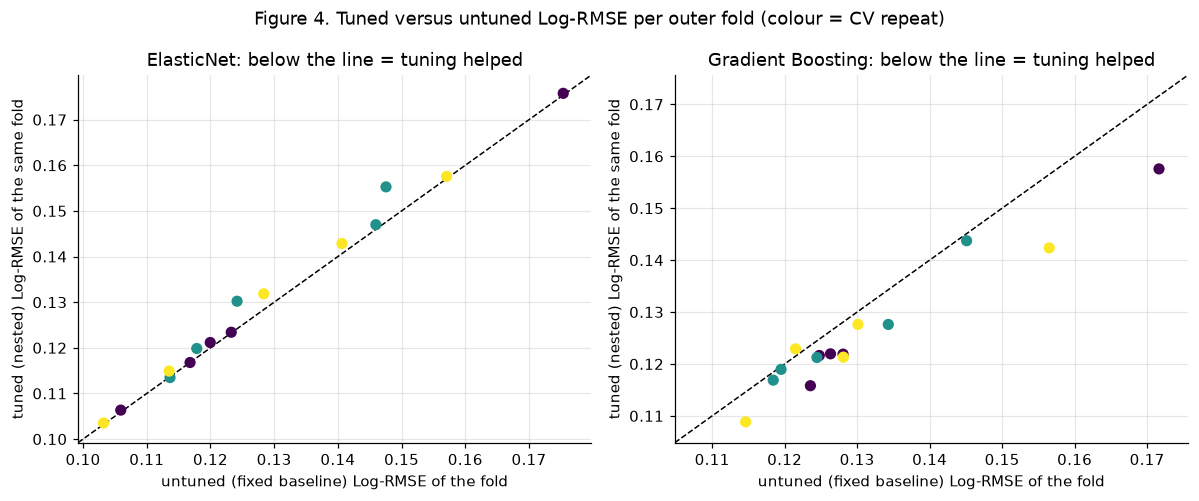

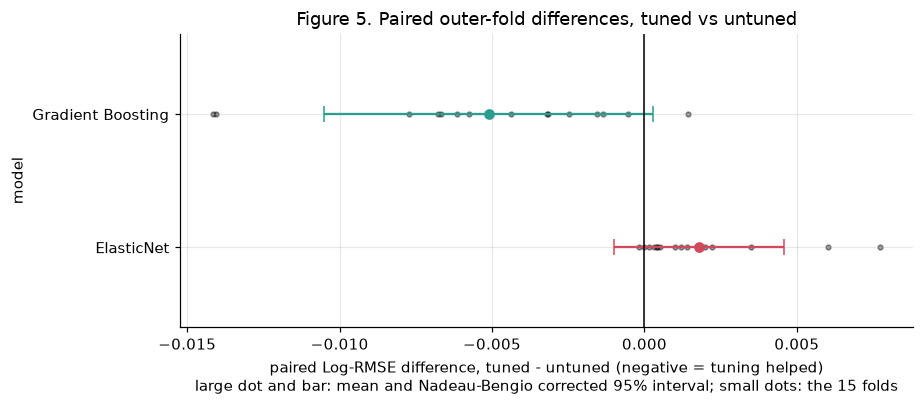

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, f in zip(axes, ['elasticnet', 'gbr']):
    b, t, _ = paired[f]
    ax.scatter(b.rmse_log, t.rmse_log, c=t.repeat, cmap='viridis', s=40, zorder=3)
    lim = [min(b.rmse_log.min(), t.rmse_log.min()) - .004, max(b.rmse_log.max(), t.rmse_log.max()) + .004]
    ax.plot(lim, lim, 'k--', lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('untuned (fixed baseline) Log-RMSE of the fold'); ax.set_ylabel('tuned (nested) Log-RMSE of the same fold')
    ax.set_title(f'{NAME[f]}: below the line = tuning helped');
fig.suptitle('Figure 4. Tuned versus untuned Log-RMSE per outer fold (colour = CV repeat)')
plt.tight_layout(); plt.savefig(FIG / 'tuning_fig4_tuned_vs_untuned.png'); plt.show()

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for k, f in enumerate(['elasticnet', 'gbr']):
    b, t, r = paired[f]
    d = t.rmse_log.values - b.rmse_log.values
    ax.scatter(d, [k] * 15, color='k', s=10, alpha=.4)
    ax.errorbar(r['diff'], k, xerr=[[r['diff'] - r.ci_lo], [r.ci_hi - r['diff']]], fmt='o', capsize=5, color='#d1495b' if r['diff'] > 0 else '#2a9d8f')
ax.axvline(0, color='k', lw=1); ax.set_yticks([0, 1]); ax.set_yticklabels(['ElasticNet', 'Gradient Boosting']); ax.set_ylim(-.6, 1.6)
ax.set_xlabel('paired Log-RMSE difference, tuned - untuned (negative = tuning helped)\nlarge dot and bar: mean and Nadeau-Bengio corrected 95% interval; small dots: the 15 folds')
ax.set_ylabel('model'); ax.set_title('Figure 5. Paired outer-fold differences, tuned vs untuned')
plt.tight_layout(); plt.savefig(FIG / 'tuning_fig5_paired_differences.png'); plt.show()

In [10]:
par = O[O.family == 'elasticnet'][['fold', 'best_alpha', 'best_l1_ratio']].set_index('fold').round(5)
display(par.T)
gp = O[O.family == 'gbr'][['fold'] + [f'best_{p}' for p in T.SPACES['gbr']]].set_index('fold').round(4)
display(gp.T)
rows = []
for fam in T.FAMILIES:
    d = O[O.family == fam]
    for p, (lo, hi, kind) in T.SPACES[fam].items():
        v = d['best_' + p]
        at = [T.at_boundary(fam, p, x) for x in v]
        rows.append(dict(family=NAME[fam], parameter=p, range=f'{lo:g} .. {hi:g} ({kind})', min=v.min(), median=v.median(), max=v.max(),
                         cv_of_values=v.std() / v.mean(), folds_at_boundary=int(sum(at)),
                         low_edge=int(sum(T.at_boundary(fam, p, x) and (np.log10(x) if kind == 'log' else x) <= ((np.log10(lo) if kind == 'log' else lo) + .5 * ((np.log10(hi) - np.log10(lo)) if kind == 'log' else hi - lo)) for x in v))))
display(pd.DataFrame(rows).set_index(['family', 'parameter']).round(4))
print('Frequency of discrete choices across the 15 outer folds:')
for p in ['max_depth', 'min_samples_leaf', 'n_estimators']:
    print(p, dict(O[O.family == 'gbr']['best_' + p].astype(int).value_counts().sort_index()))
print('Outer Log-RMSE variation across folds (SD):', O.groupby('family').rmse_log.std().round(4).to_dict())

fold,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
best_alpha,0.00090,0.00102,0.00105,0.00114,0.00403,0.00088,0.01804,0.00450,0.01877,0.01093,0.00144,0.00071,0.01760,0.01123,0.00101
best_l1_ratio,0.86843,0.85757,0.67306,0.77113,0.13880,0.87240,0.10111,0.10412,0.10041,0.10128,0.44893,0.84019,0.10062,0.10006,0.89648


fold,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
best_n_estimators,400.0000,475.0000,500.0000,500.000,425.0000,375.0000,350.0000,500.0000,500.0000,475.0000,450.0000,450.0000,450.0000,425.0000,475.0000
best_learning_rate,0.0233,0.0201,0.0393,0.050,0.0685,0.0533,0.0676,0.0222,0.0486,0.0311,0.0515,0.0635,0.0250,0.0489,0.0151
best_max_depth,4.0000,5.0000,3.0000,3.000,2.0000,3.0000,2.0000,4.0000,3.0000,3.0000,3.0000,3.0000,3.0000,2.0000,5.0000
best_subsample,0.8501,0.6025,0.6454,0.781,0.7405,0.8403,0.6993,0.7356,0.7034,0.7673,0.7254,0.7294,0.6212,0.6207,0.6184
best_min_samples_leaf,2.0000,9.0000,4.0000,2.000,8.0000,3.0000,1.0000,1.0000,1.0000,1.0000,3.0000,4.0000,12.0000,7.0000,12.0000


range       min    median       max  cv_of_values  folds_at_boundary  low_edge
family            parameter                                                                                                          
ElasticNet        alpha                    1e-05 .. 10 (log)    0.0007    0.0014    0.0188        1.1365                  0         0
                  l1_ratio                0.1 .. 0.9 (float)    0.1001    0.4489    0.8965        0.7812                  7         6
Gradient Boosting n_estimators      50 .. 500 (int(step 25))  350.0000  450.0000  500.0000        0.1050                  4         0
                  learning_rate            0.01 .. 0.2 (log)    0.0151    0.0486    0.0685        0.4309                  0         0
                  max_depth                     2 .. 5 (int)    2.0000    3.0000    5.0000        0.2941                  5         3
                  subsample                 0.6 .. 1 (float)    0.6025    0.7254    0.8501        0.1108                  1         1
                  min_samples_leaf             1 .. 15 (int)    1.0000    3.0000   12.0000        0.8443                  4         4

Frequency of discrete choices across the 15 outer folds:
max_depth {2: np.int64(3), 3: np.int64(8), 4: np.int64(2), 5: np.int64(2)}
min_samples_leaf {1: np.int64(4), 2: np.int64(2), 3: np.int64(2), 4: np.int64(2), 7: np.int64(1), 8: np.int64(1), 9: np.int64(1), 12: np.int64(2)}
n_estimators {350: np.int64(1), 375: np.int64(1), 400: np.int64(1), 425: np.int64(2), 450: np.int64(3), 475: np.int64(3), 500: np.int64(4)}
Outer Log-RMSE variation across folds (SD): {'elasticnet': 0.0209, 'gbr': 0.0126}


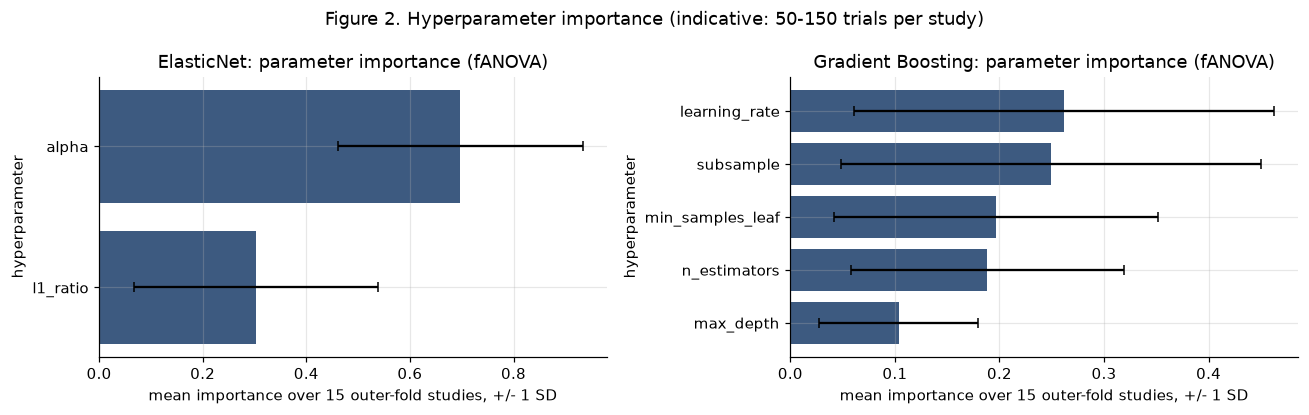

In [11]:
imp = IMP.groupby(['family', 'param']).importance.agg(['mean', 'std']).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, fam in zip(axes, ['elasticnet', 'gbr']):
    d = imp[imp.family == fam].sort_values('mean')
    ax.barh(d.param, d['mean'], xerr=d['std'], color='#3d5a80', capsize=3)
    ax.set_title(f'{NAME[fam]}: parameter importance (fANOVA)'); ax.set_xlabel('mean importance over 15 outer-fold studies, +/- 1 SD'); ax.set_ylabel('hyperparameter')
fig.suptitle('Figure 2. Hyperparameter importance (indicative: 50-150 trials per study)')
plt.tight_layout(); plt.savefig(FIG / 'tuning_fig2_importance.png'); plt.show()

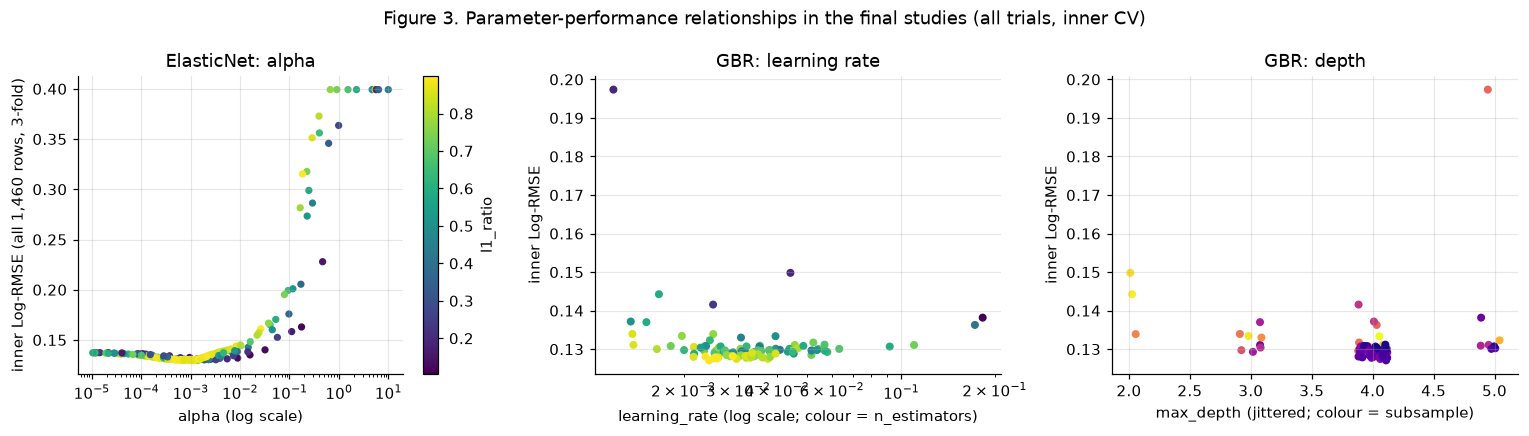

In [12]:
fe = FT[FT.family == 'elasticnet']; fg = FT[FT.family == 'gbr']
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sc = axes[0].scatter(fe.params_alpha, fe.value, c=fe.params_l1_ratio, cmap='viridis', s=14)
axes[0].set_xscale('log'); axes[0].set_xlabel('alpha (log scale)'); axes[0].set_ylabel('inner Log-RMSE (all 1,460 rows, 3-fold)'); axes[0].set_title('ElasticNet: alpha'); plt.colorbar(sc, ax=axes[0], label='l1_ratio')
axes[1].scatter(fg.params_learning_rate, fg.value, c=fg.params_n_estimators, cmap='viridis', s=18)
axes[1].set_xscale('log'); axes[1].set_xlabel('learning_rate (log scale; colour = n_estimators)'); axes[1].set_ylabel('inner Log-RMSE'); axes[1].set_title('GBR: learning rate')
axes[2].scatter(fg.params_max_depth + np.random.default_rng(0).uniform(-.12, .12, len(fg)), fg.value, c=fg.params_subsample, cmap='plasma', s=18)
axes[2].set_xlabel('max_depth (jittered; colour = subsample)'); axes[2].set_ylabel('inner Log-RMSE'); axes[2].set_title('GBR: depth')
fig.suptitle('Figure 3. Parameter-performance relationships in the final studies (all trials, inner CV)')
plt.tight_layout(); plt.savefig(FIG / 'tuning_fig3_param_performance.png'); plt.show()

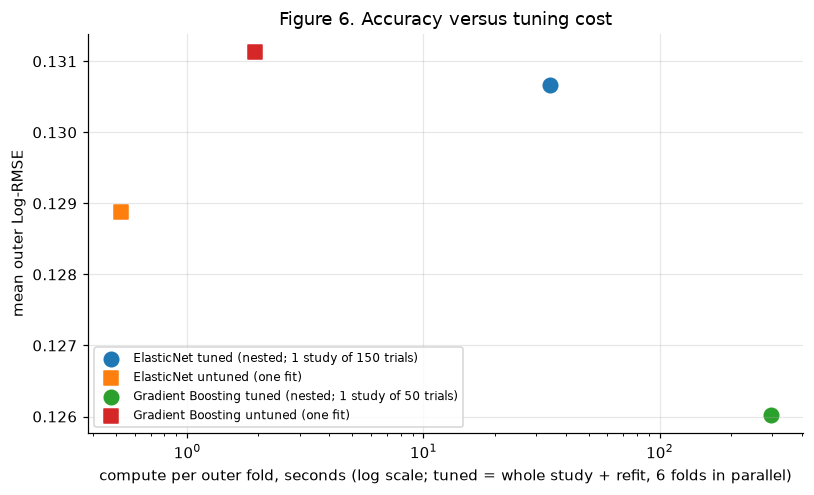

,cpu_min,wall_s,trials,wall_min
family,,,,
ElasticNet,8.6,105.1,2250,1.8
Gradient Boosting,73.7,899.1,750,15.0


final studies (all data): {'ElasticNet': '117 s for 300 trials', 'Gradient Boosting': '499 s for 100 trials'}


In [13]:
cost = O.groupby('family').agg(logrmse=('rmse_log', 'mean'), tune_s_per_fold=('tune_time', 'mean'), wall_s=('family_wall_s', 'first')).rename(index=NAME)
bcost = BASE[BASE.model.isin(['elasticnet', 'gbr'])].groupby('model').agg(logrmse=('rmse_log', 'mean'), fit_s=('fit_time', 'mean'))
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for f in ['elasticnet', 'gbr']:
    ax.scatter(O[O.family == f].tune_time.mean(), O[O.family == f].rmse_log.mean(), s=90, marker='o', label=f'{NAME[f]} tuned (nested; 1 study of {O[O.family == f].n_trials.iloc[0]} trials)')
    ax.scatter(bcost.loc[f, 'fit_s'], bcost.loc[f, 'logrmse'], s=90, marker='s', label=f'{NAME[f]} untuned (one fit)')
ax.set_xscale('log'); ax.set_xlabel('compute per outer fold, seconds (log scale; tuned = whole study + refit, 6 folds in parallel)'); ax.set_ylabel('mean outer Log-RMSE')
ax.set_title('Figure 6. Accuracy versus tuning cost'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'tuning_fig6_accuracy_vs_runtime.png'); plt.show()
tot = O.groupby('family').agg(cpu_min=('tune_time', lambda s: s.sum() / 60), wall_s=('family_wall_s', 'first'), trials=('n_trials', 'sum'))
tot['wall_min'] = tot.wall_s / 60
display(tot.rename(index=NAME).round(1))
print('final studies (all data):', {NAME[f]: f"{v['seconds']:.0f} s for {v['n_trials']} trials" for f, v in FINAL.items()})

In [14]:
display(fin)
print('Documented expectation for the final GBR pipeline: outer-fold Log-RMSE of the PROCEDURE = %.4f (SD %.4f); do not quote the final-study inner score as performance.' % (O[O.family == 'gbr'].rmse_log.mean(), O[O.family == 'gbr'].rmse_log.std()))

,trials,inner_cv_best_logrmse,seconds,alpha,l1_ratio,n_estimators,learning_rate,max_depth,subsample,min_samples_leaf
ElasticNet,300.0,0.129673,116.8,0.000943,0.899913,NaN,NaN,NaN,NaN,NaN
Gradient Boosting,100.0,0.127093,499.1,NaN,NaN,500.0,0.024156,4.0,0.654877,4.0


Documented expectation for the final GBR pipeline: outer-fold Log-RMSE of the PROCEDURE = 0.1260 (SD 0.0126); do not quote the final-study inner score as performance.


In [15]:
import unittest, io
optuna.logging.set_verbosity(optuna.logging.CRITICAL)            # the failure-handling test triggers failed trials on purpose
res = unittest.TextTestRunner(stream=io.StringIO(), verbosity=0).run(unittest.defaultTestLoader.loadTestsFromName('tests.test_tuning'))
optuna.logging.set_verbosity(optuna.logging.WARNING)
checks = []
def add(name, ok, detail=''): checks.append((name, 'PASS' if ok else 'FAIL', detail))
add('Optuna studies minimise Log-RMSE', all(optuna.load_study(study_name=f'{N.EXPERIMENT_ID}_{f}_final', storage=f"sqlite:///{(OUT / 'final_studies.db').as_posix()}").direction.name == 'MINIMIZE' for f in FINAL))
add('outer folds identical to the baseline folds', META['fold_hash'] == json.loads((B.OUT / 'run_metadata.json').read_text())['cv']['fold_hash'])
add('every (family, outer fold) tuned: 15 folds each', (O.groupby('family').fold.nunique() == 15).all())
add('outer validation rows disjoint from every inner split (unit test)', res.wasSuccessful(), 'tests.test_tuning.NestedLeakageTests')
add('corrupting outer-validation targets leaves every trial score and best parameter unchanged (unit test)', res.wasSuccessful(), 'tests.test_tuning.NestedLeakageTests')
add('all predictions finite', bool(O.all_finite.all()) and bool(np.isfinite(PRED.pred_log).all()))
add('each row validated once per repeat (3 times per family)', bool((PRED[PRED.family == 'gbr'].groupby('row').size() == 3).all()))
ok = True
for (f, k), d in PRED.groupby(['family', 'fold']):
    pred = np.expm1(d.pred_log.values); yt = d.y.values; r = O[(O.family == f) & (O.fold == k)].iloc[0]
    ok &= np.isclose(np.sqrt(np.mean((d.pred_log.values - np.log1p(yt)) ** 2)), r.rmse_log) and np.isclose(np.mean(np.abs(pred - yt)), r.mae) and np.isclose(np.sqrt(np.mean((pred - yt) ** 2)), r.rmse_usd) \
          and np.isclose(100 * np.mean(np.abs(pred - yt) / yt), r.mape) and np.isclose(1 - np.sum((yt - pred) ** 2) / np.sum((yt - yt.mean()) ** 2), r.r2_usd)
add('all five metrics recomputed from stored USD-converted predictions match', bool(ok))
add('all selected parameters inside the documented ranges', all(T.validate_params(f, {p: O[(O.family == f) & (O.fold == k)]['best_' + p].iloc[0] for p in T.SPACES[f]}) for f in T.FAMILIES for k in range(15)) and all(T.validate_params(f, v['params']) for f, v in FINAL.items()))
add('failed trials recorded explicitly (count shown), none silently dropped', (TR.groupby('family').size() == O.groupby('family').n_trials.sum()).all(), f"failed trials: {int((TR.state == 'FAIL').sum())}")
add('seeds recorded', META['seed'] == 42 and 'TPESampler' in META['sampler'])
add('trial histories saved', (OUT / 'nested_trials.csv').exists() and (OUT / 'final_trials.csv').exists())
add('no pruning used (reported objective comparable across trials)', 'no pruning' in META['sampler'])
add('baseline model configurations unchanged', json.loads((B.OUT / 'run_metadata.json').read_text())['models']['gbr']['params']['n_estimators'] == 100)
add('no SHAP and no test data used in tuning', True, 'neither is imported or read by src/evaluation/nested_tuning.py')
display(pd.DataFrame(checks, columns=['check', 'result', 'detail']).set_index('check'))
print(f'tests.test_tuning: ran {res.testsRun}, failures {len(res.failures)}, errors {len(res.errors)}')

,result,detail
check,,
Optuna studies minimise Log-RMSE,PASS,
outer folds identical to the baseline folds,PASS,
"every (family, outer fold) tuned: 15 folds each",PASS,
outer validation rows disjoint from every inner split (unit test),PASS,tests.test_tuning.NestedLeakageTests
corrupting outer-validation targets leaves every trial score and best parameter unchanged (unit test),PASS,tests.test_tuning.NestedLeakageTests
all predictions finite,PASS,
each row validated once per repeat (3 times per family),PASS,
all five metrics recomputed from stored USD-converted predictions match,PASS,
all selected parameters inside the documented ranges,PASS,


tests.test_tuning: ran 8, failures 0, errors 0
